In [2]:
import numpy as np
import matplotlib.pyplot as plt 
import pandas as pd
from sklearn import linear_model

In [3]:
df = pd.read_csv("tehran_house_prices.csv")
df.head()


,متراژ,تعداد_اتاق,سن_بنا,طبقه,تعداد_کل_طبقات,پارکینگ,آسانسور,انباری,منطقه,قیمت
0,208,5,7,0,9,1,1,0,جردن,16946000000
1,218,5,34,2,14,0,1,0,سعادت‌آباد,9252000000
2,174,4,1,6,14,1,1,1,ستارخان,9931000000
3,46,1,10,13,13,1,1,0,پونک,2925000000
4,131,3,6,2,13,0,1,1,تهرانپارس,5880000000


In [4]:
df.describe()

,متراژ,تعداد_اتاق,سن_بنا,طبقه,تعداد_کل_طبقات,پارکینگ,آسانسور,انباری,قیمت
count,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,3.000000e+02
mean,149.643333,3.303333,18.693333,7.516667,10.670000,0.736667,0.980000,0.670000,8.056730e+09
std,57.909364,1.292371,10.514171,4.616720,3.687786,0.441178,0.140234,0.470998,4.061055e+09
min,46.000000,1.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.442000e+09
25%,104.750000,2.000000,9.000000,4.000000,8.000000,0.000000,1.000000,0.000000,4.803500e+09
50%,147.000000,3.000000,19.000000,8.000000,11.000000,1.000000,1.000000,1.000000,7.355000e+09
75%,200.000000,4.000000,28.000000,11.000000,14.000000,1.000000,1.000000,1.000000,1.080000e+10
max,250.000000,5.000000,35.000000,15.000000,16.000000,1.000000,1.000000,1.000000,2.129600e+10


In [5]:
cdf = df[["متراژ", "تعداد_اتاق", "سن_بنا", "طبقه", "تعداد_کل_طبقات", "پارکینگ", "آسانسور", "انباری", "قیمت"]]
cdf.head(6)

,متراژ,تعداد_اتاق,سن_بنا,طبقه,تعداد_کل_طبقات,پارکینگ,آسانسور,انباری,قیمت
0,208,5,7,0,9,1,1,0,16946000000
1,218,5,34,2,14,0,1,0,9252000000
2,174,4,1,6,14,1,1,1,9931000000
3,46,1,10,13,13,1,1,0,2925000000
4,131,3,6,2,13,0,1,1,5880000000
5,56,1,29,3,13,0,1,1,1943000000


Text(0, 0.5, 'price')

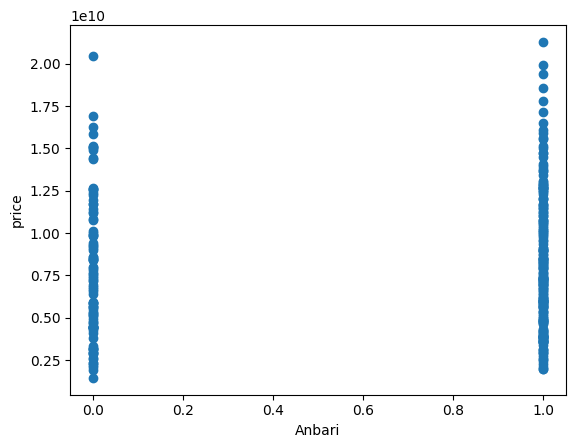

In [6]:
plt.scatter(cdf.انباری, cdf.قیمت)
plt.xlabel("Anbari")
plt.ylabel("price")


Text(0, 0.5, 'price')

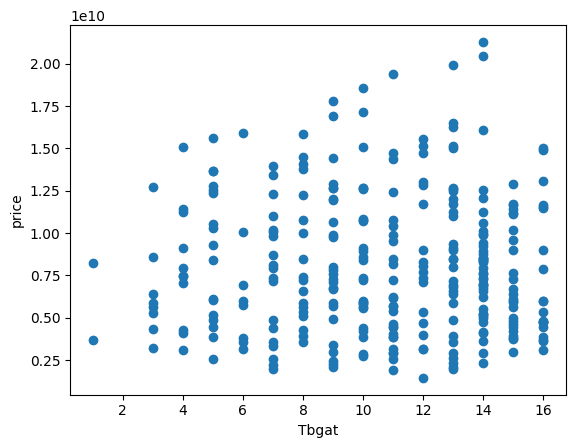

In [7]:
plt.scatter(cdf.تعداد_کل_طبقات, cdf.قیمت)
plt.xlabel("Tbgat")
plt.ylabel("price")

In [1]:
plt.scatter(cdf.متراژ, cdf.قیمت)
plt.xlabel("متراژ")
plt.ylabel("قیمت")

NameError: name 'plt' is not defined

In [9]:
msk = np.random.rand(len(df)) < 0.8
train = cdf[msk]
test = cdf[~msk]

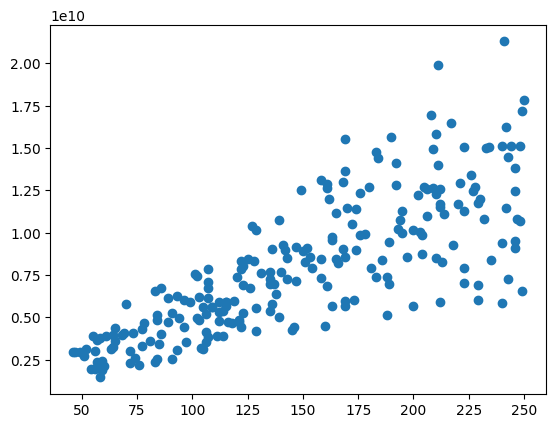

In [10]:
plt.scatter(train.متراژ, train.قیمت)

Text(0, 0.5, 'price')

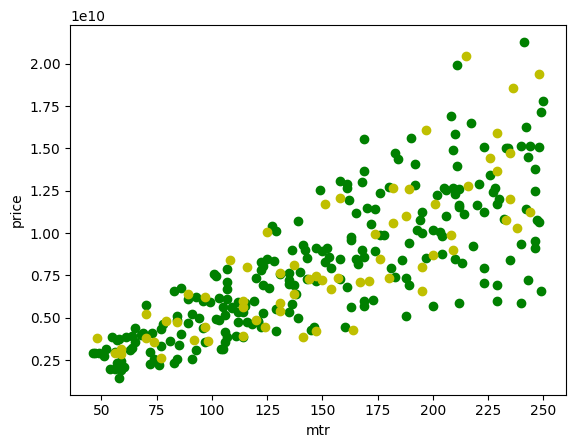

In [11]:
fig = plt.figure()
ax1 = fig.add_subplot(111)
ax1.scatter(train.متراژ, train.قیمت, color="g")
ax1.scatter(test.متراژ, test.قیمت, c="y")
plt.xlabel("mtr")
plt.ylabel("price")

In [12]:
regr = linear_model.LinearRegression()
train_x = np.asanyarray(train[["متراژ"]])
train_y = np.asanyarray(train[["قیمت"]])
regr.fit(train_x, train_y)
print(f"Coefficients: {regr.coef_}\nIntercept: {regr.intercept_}")


Coefficients: [[54156393.61616676]]
Intercept: [-82390367.71241188]


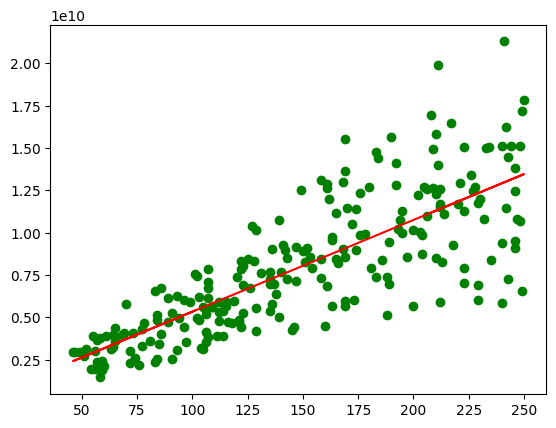

In [13]:
plt.scatter(train.متراژ, train.قیمت,  c="g")
plt.plot(train_x, regr.coef_[0][0]*train_x + regr.intercept_[0], 'r')

In [14]:
from sklearn.metrics import r2_score
test_x = np.asanyarray(test[["متراژ"]])
test_y = np.asanyarray(test[["قیمت"]])
test_y_ = regr.predict(test_x)
print("Mean absolute error: %.2f" % np.mean(np.absolute(test_y_ - test_y)))
print("Residual sum of squares (MSE): %.2f" % np.mean((test_y_ - test_y) ** 2))
print("R2-score: %.2f" % r2_score(test_y , test_y_) )

Mean absolute error: 1914664951.09
Residual sum of squares (MSE): 6295805681545565184.00
R2-score: 0.65
